Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_diabetes

Load dataset

In [2]:
diabetes = load_diabetes()
df = pd.DataFrame(
    diabetes.data,
    columns=diabetes.feature_names
)
df["target"] = diabetes.target
df.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


Dataset information

In [3]:
print(df.shape)
df.info()

(442, 11)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     442 non-null    float64
 1   sex     442 non-null    float64
 2   bmi     442 non-null    float64
 3   bp      442 non-null    float64
 4   s1      442 non-null    float64
 5   s2      442 non-null    float64
 6   s3      442 non-null    float64
 7   s4      442 non-null    float64
 8   s5      442 non-null    float64
 9   s6      442 non-null    float64
 10  target  442 non-null    float64
dtypes: float64(11)
memory usage: 38.1 KB


Missing values

In [5]:
print(df.isnull().sum())

age       0
sex       0
bmi       0
bp        0
s1        0
s2        0
s3        0
s4        0
s5        0
s6        0
target    0
dtype: int64


Statistical summary

In [7]:
df.describe()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
count,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,442.000000
mean,-2.511817e-19,1.230790e-17,-2.245564e-16,-4.797570e-17,-1.381499e-17,3.918434e-17,-5.777179e-18,-9.042540e-18,9.293722e-17,1.130318e-17,152.133484
std,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,77.093005
min,-1.072256e-01,-4.464164e-02,-9.027530e-02,-1.123988e-01,-1.267807e-01,-1.156131e-01,-1.023071e-01,-7.639450e-02,-1.260971e-01,-1.377672e-01,25.000000
25%,-3.729927e-02,-4.464164e-02,-3.422907e-02,-3.665608e-02,-3.424784e-02,-3.035840e-02,-3.511716e-02,-3.949338e-02,-3.324559e-02,-3.317903e-02,87.000000
50%,5.383060e-03,-4.464164e-02,-7.283766e-03,-5.670422e-03,-4.320866e-03,-3.819065e-03,-6.584468e-03,-2.592262e-03,-1.947171e-03,-1.077698e-03,140.500000
75%,3.807591e-02,5.068012e-02,3.124802e-02,3.564379e-02,2.835801e-02,2.984439e-02,2.931150e-02,3.430886e-02,3.243232e-02,2.791705e-02,211.500000
max,1.107267e-01,5.068012e-02,1.705552e-01,1.320436e-01,1.539137e-01,1.987880e-01,1.811791e-01,1.852344e-01,1.335973e-01,1.356118e-01,346.000000


Separate X and y

In [8]:
X = df.drop("target", axis=1)
y = df["target"]

Train-test split and normalization

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Exploratory Data Analysis (EDA)


Exploratory Data Analysis is performed to understand the
distribution, patterns, relationships, and characteristics
of the dataset before building the ANN model.

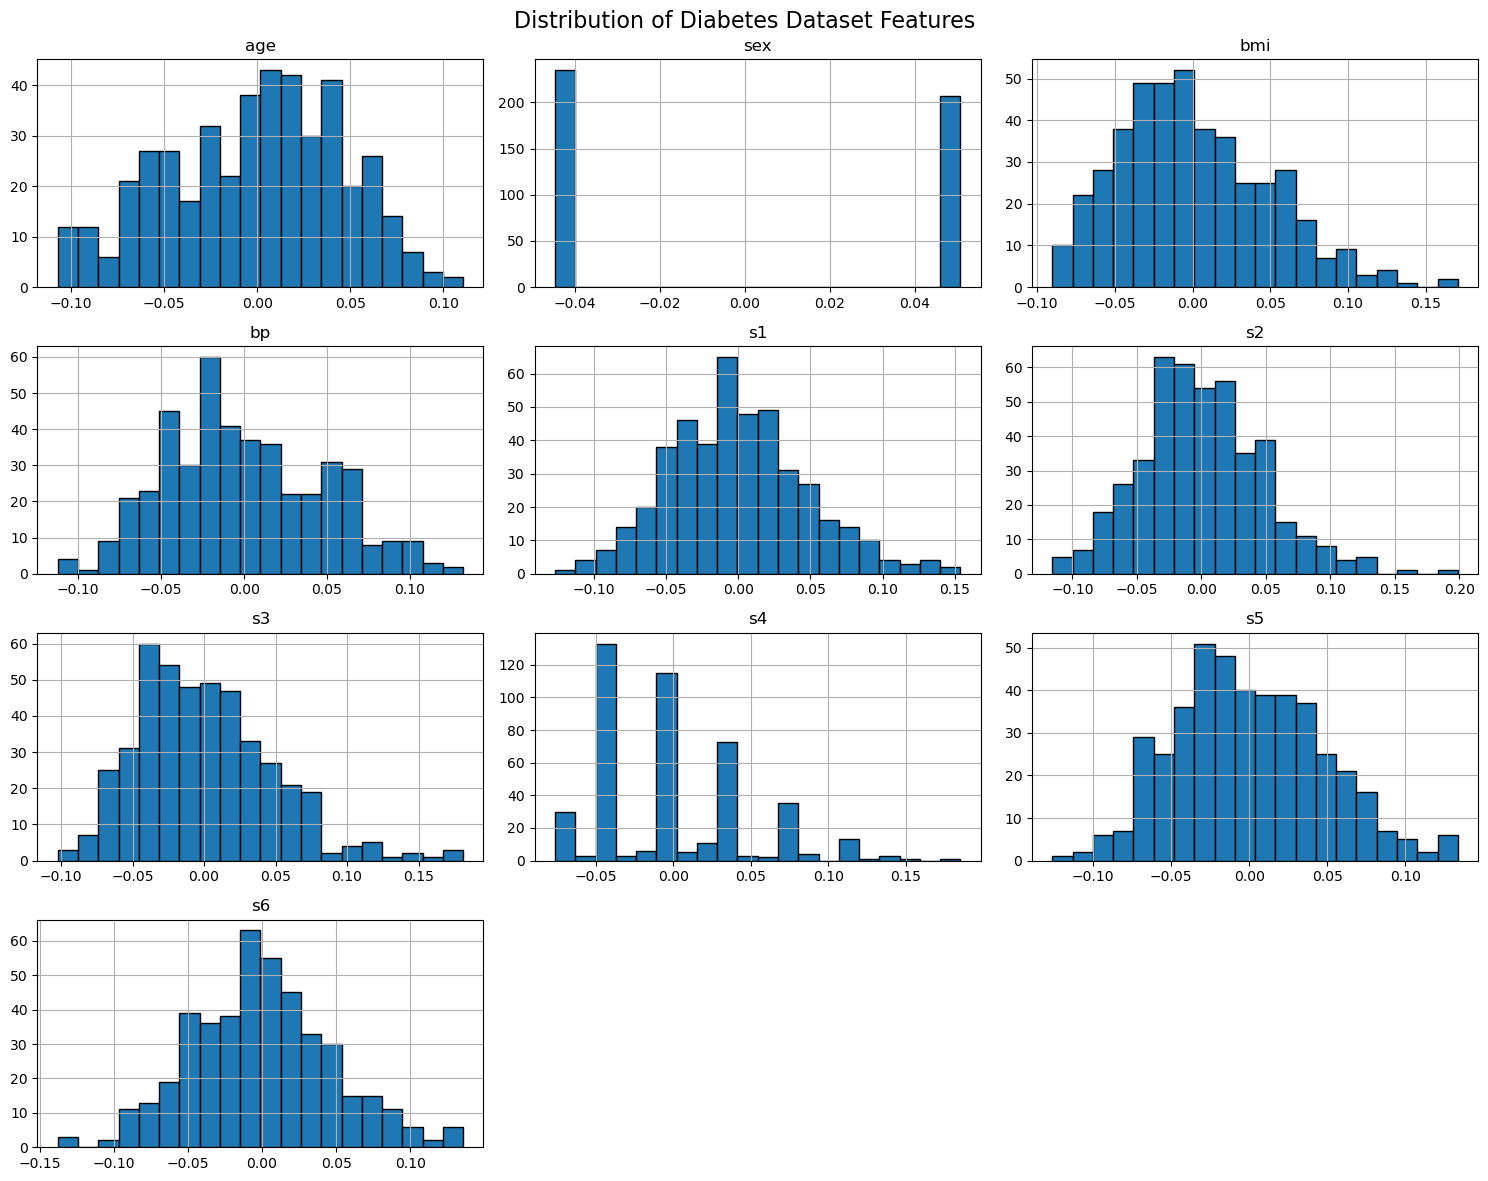

In [11]:
# Plot distributions of all independent variables

X.hist(figsize=(15, 12), bins=20, edgecolor="black")

plt.suptitle("Distribution of Diabetes Dataset Features", fontsize=16)

plt.tight_layout()
plt.show()

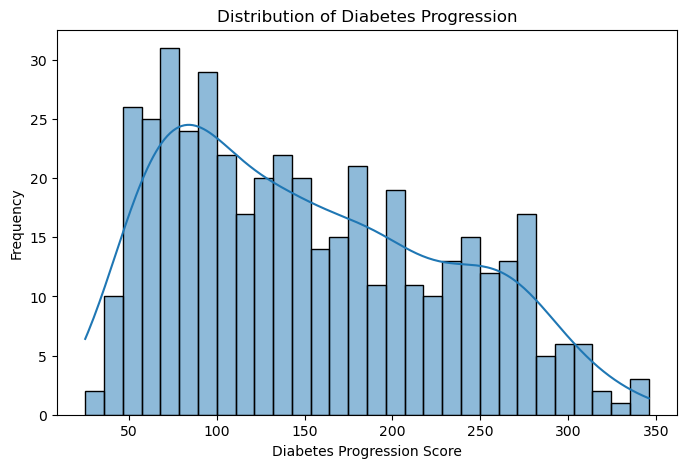

In [12]:
plt.figure(figsize=(8, 5))

sns.histplot(y, bins=30, kde=True)

plt.title("Distribution of Diabetes Progression")
plt.xlabel("Diabetes Progression Score")
plt.ylabel("Frequency")

plt.show()

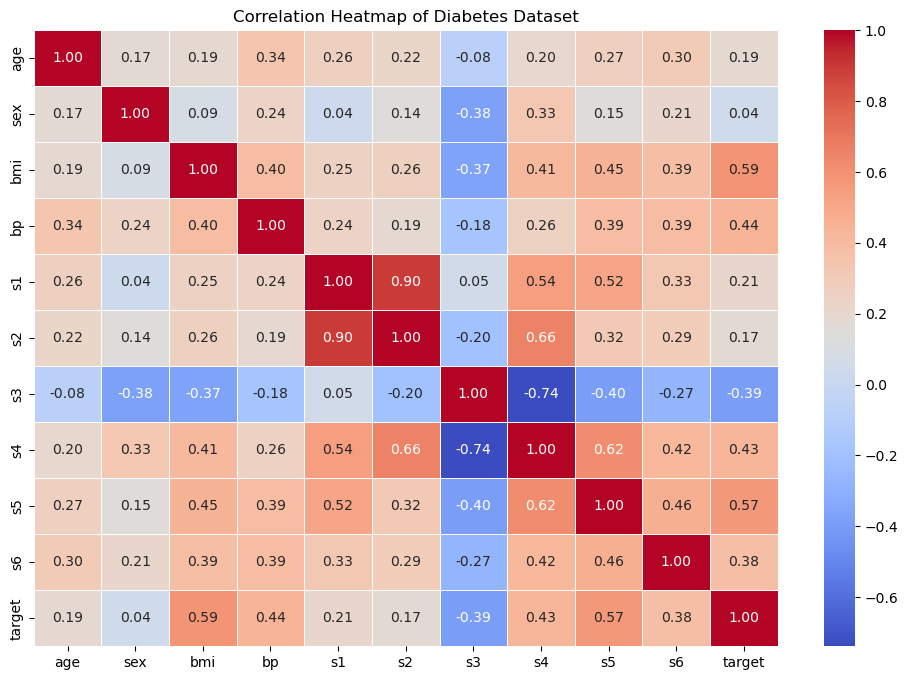

In [13]:
# Calculate correlation matrix
correlation_matrix = df.corr()

# Create heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Diabetes Dataset")

plt.show()

In [14]:
# Calculate correlation with target
target_correlation = df.corr()["target"].drop("target")

# Sort correlations
target_correlation = target_correlation.sort_values(
    ascending=False
)

print(target_correlation)

bmi    0.586450
s5     0.565883
bp     0.441482
s4     0.430453
s6     0.382483
s1     0.212022
age    0.187889
s2     0.174054
sex    0.043062
s3    -0.394789
Name: target, dtype: float64


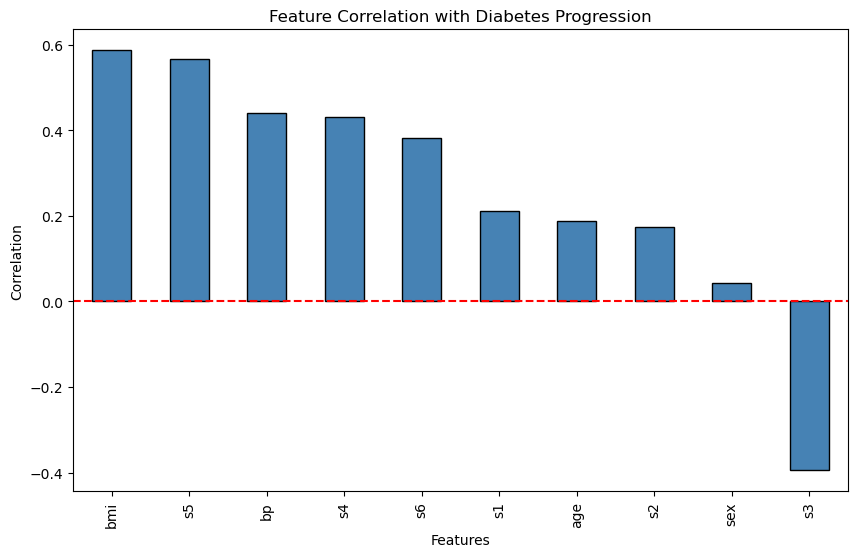

In [15]:
plt.figure(figsize=(10, 6))

target_correlation.plot(
    kind="bar",
    color="steelblue",
    edgecolor="black"
)

plt.title("Feature Correlation with Diabetes Progression")
plt.xlabel("Features")
plt.ylabel("Correlation")

plt.axhline(y=0, color="red", linestyle="--")

plt.show()

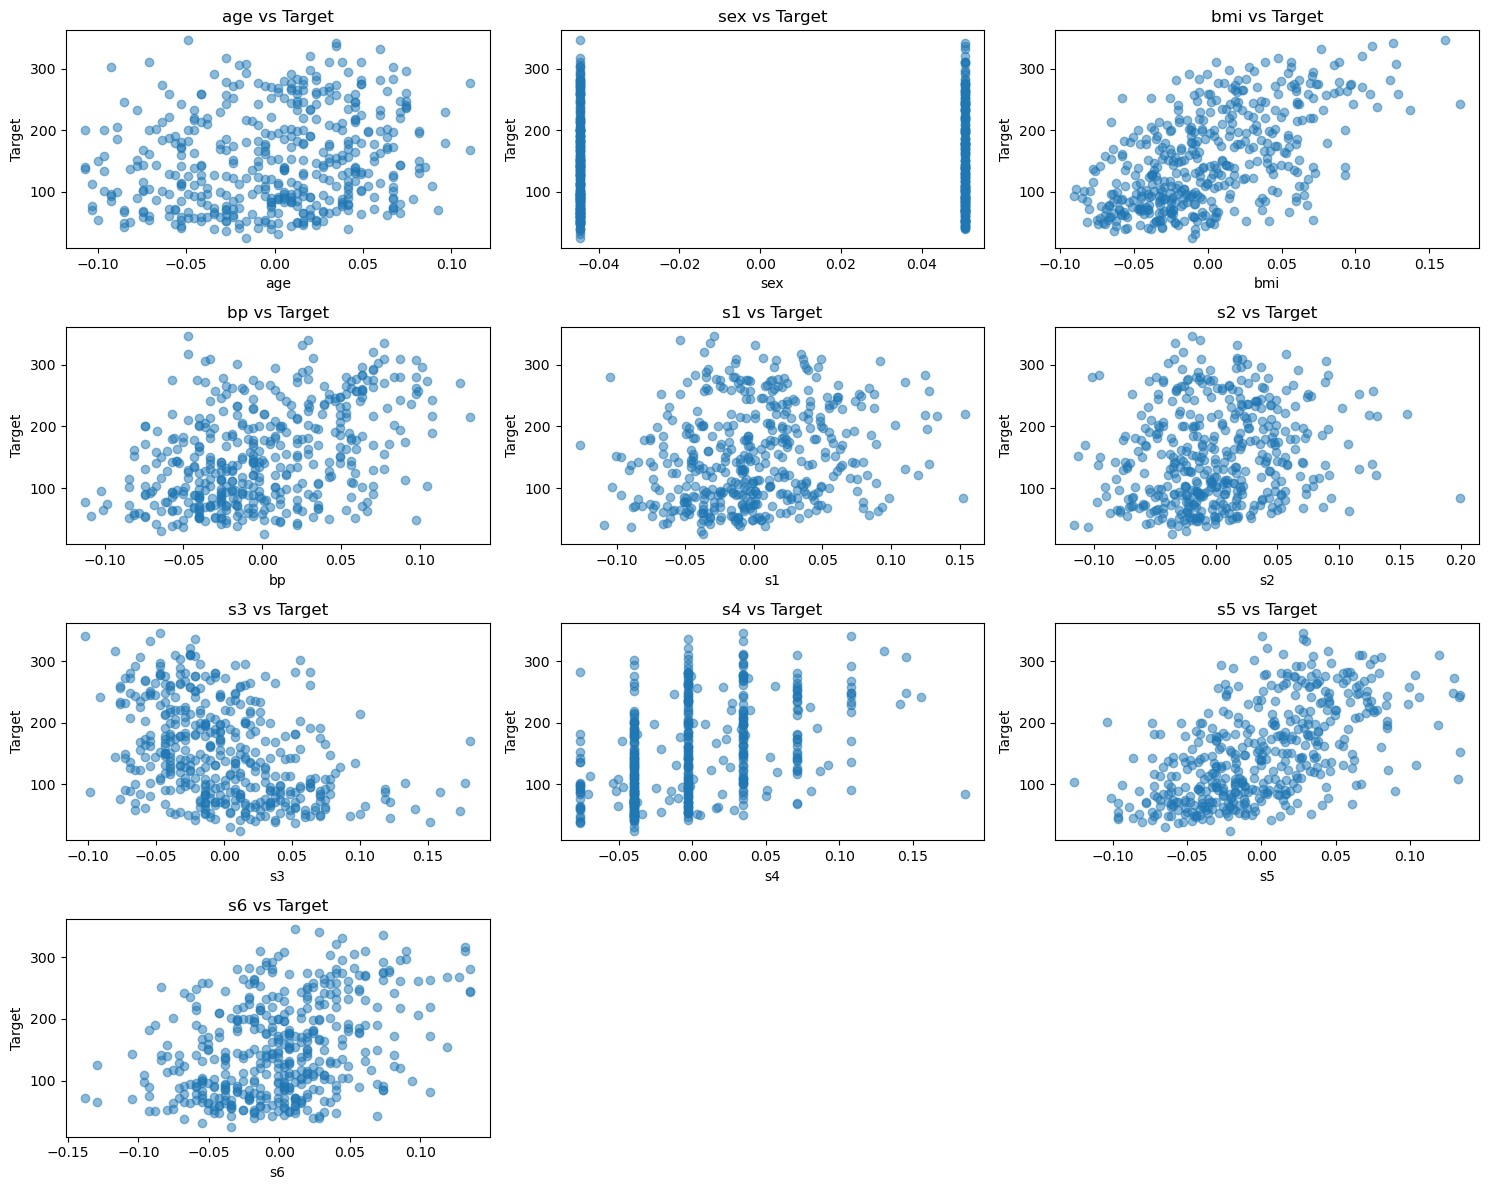

In [17]:
# Plot each feature against the target

plt.figure(figsize=(15, 12))

for i, column in enumerate(X.columns):
    plt.subplot(4, 3, i + 1)

    plt.scatter(
        X[column],
        y,
        alpha=0.5
    )

    plt.xlabel(column)
    plt.ylabel("Target")
    plt.title(f"{column} vs Target")

plt.tight_layout()
plt.show()

##  Building the Artificial Neural Network

In [ ]:
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input

print("TensorFlow version:", tf.__version__)

Build ANN Architecture

In [20]:
from tensorflow.keras import Input
from tensorflow.keras.layers import Dense
from tensorflow.keras.models import Sequential

# Initialize ANN model
model = Sequential([
    # Input layer
    Input(shape=(10,)),
    # First hidden layer
    Dense(64, activation="relu"),
    # Second hidden layer
    Dense(32, activation="relu"),
    # Output layer
    Dense(1, activation="linear"),
])

print("ANN model created successfully!")

ANN model created successfully!


In [21]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,817 (11.00 KB)

 Trainable params: 2,817 (11.00 KB)

 Non-trainable params: 0 (0.00 B)

Compile the ANN model

In [22]:
model.compile(
    optimizer='adam',
    loss='mean_squared_error',
    metrics=['mae']
)

print("Model compiled successfully!")

Model compiled successfully!


##  Training the Artificial Neural Network

In [23]:
# Train the ANN model

history = model.fit(
    X_train_scaled,
    y_train,
    epochs=100,
    batch_size=16,
    validation_split=0.2,
    verbose=1
)

Epoch 1/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 31353.8730 - mae: 158.1745 - val_loss: 22187.2891 - val_mae: 133.0642
Epoch 2/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 30954.3086 - mae: 156.9971 - val_loss: 21814.9570 - val_mae: 131.7762
Epoch 3/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 30347.1602 - mae: 155.2323 - val_loss: 21243.8066 - val_mae: 129.8174
Epoch 4/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 29322.4590 - mae: 152.2819 - val_loss: 20325.3125 - val_mae: 126.6464
Epoch 5/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 27722.3105 - mae: 147.6153 - val_loss: 19004.0781 - val_mae: 121.9883
Epoch 6/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 25423.4199 - mae: 140.6883 - val_loss: 17251.0801 - val_mae: 115.5508
Epoch 7/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 22487.0410 - mae: 131.3234 - val_loss: 15100.1250 - val_mae: 107.1048
Epoch 8/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 18999.7871 - mae: 119.1705 - val_loss

Visualize the training loss

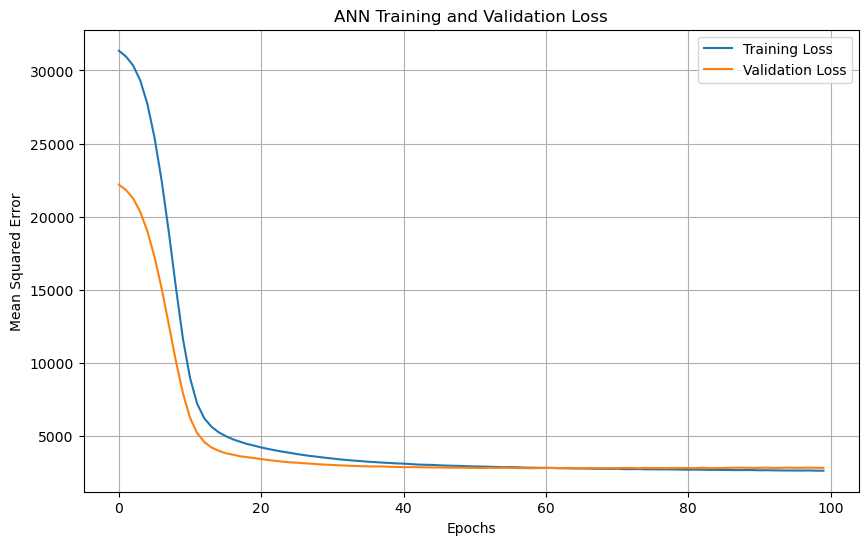

In [25]:
plt.figure(figsize=(10, 6))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('ANN Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Mean Squared Error')

plt.legend()
plt.grid(True)

plt.show()

Visualize MAE

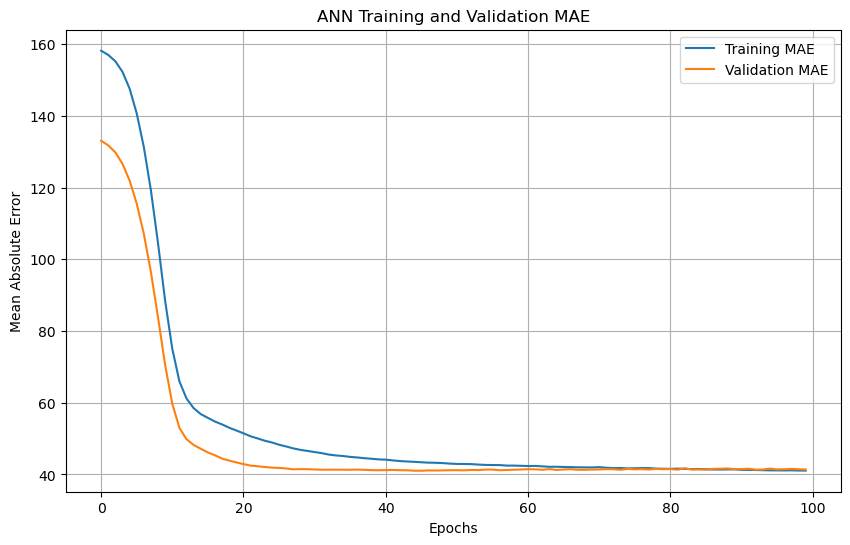

In [26]:
plt.figure(figsize=(10, 6))

plt.plot(history.history['mae'], label='Training MAE')
plt.plot(history.history['val_mae'], label='Validation MAE')

plt.title('ANN Training and Validation MAE')
plt.xlabel('Epochs')
plt.ylabel('Mean Absolute Error')

plt.legend()
plt.grid(True)

plt.show()

#  Model Evaluation

In [27]:
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import r2_score
import numpy as np

Make predictions

In [29]:
# Predict using testing data

y_pred = model.predict(X_test_scaled)

# Convert predictions into a 1D array
y_pred = y_pred.flatten()

print("First 10 Actual Values:")
print(y_test[:10].values)

print("\nFirst 10 Predicted Values:")
print(y_pred[:10])

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step 
First 10 Actual Values:
[219.  70. 202. 230. 111.  84. 242. 272.  94.  96.]

First 10 Predicted Values:
[168.86429 191.64847 153.7786  299.8824   98.13069 123.71832 266.3694
 177.34494  83.29419  73.75046]


In [30]:
mse = mean_squared_error(y_test, y_pred)

print("Mean Squared Error:", mse)

Mean Squared Error: 2850.588630176178


In [31]:
rmse = np.sqrt(mse)

print("Root Mean Squared Error:", rmse)

Root Mean Squared Error: 53.39090400223785


In [32]:
mae = mean_absolute_error(y_test, y_pred)

print("Mean Absolute Error:", mae)

Mean Absolute Error: 42.82435487897209


In [33]:
r2 = r2_score(y_test, y_pred)

print("R2 Score:", r2)

R2 Score: 0.4619654616396561


In [34]:
results = pd.DataFrame({
    "Metric": ["MSE", "RMSE", "MAE", "R2 Score"],
    "Value": [mse, rmse, mae, r2]
})

print(results)

     Metric        Value
0       MSE  2850.588630
1      RMSE    53.390904
2       MAE    42.824355
3  R2 Score     0.461965


Actual vs Predicted visualization

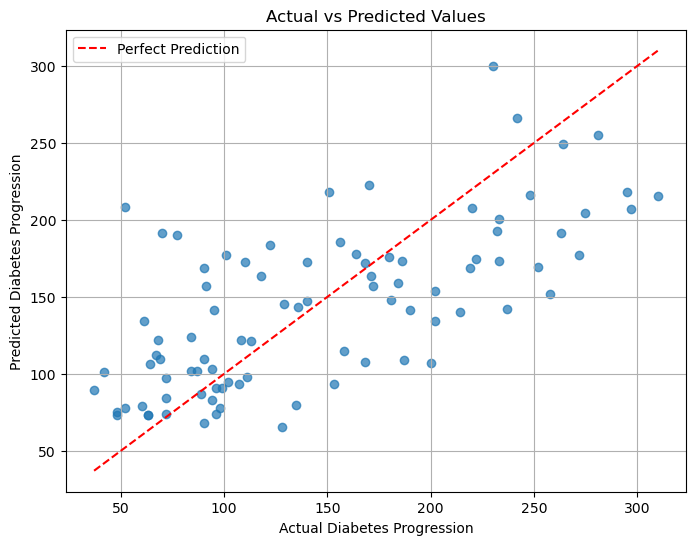

In [35]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.7)

# Perfect prediction reference line
min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    color="red",
    linestyle="--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Diabetes Progression")
plt.ylabel("Predicted Diabetes Progression")

plt.title("Actual vs Predicted Values")

plt.legend()
plt.grid(True)

plt.show()

In [36]:
baseline_results = {
    "Model": "Baseline ANN",
    "MSE": mse,
    "RMSE": rmse,
    "MAE": mae,
    "R2 Score": r2
}

baseline_df = pd.DataFrame([baseline_results])

baseline_df

,Model,MSE,RMSE,MAE,R2 Score
0,Baseline ANN,2850.58863,53.390904,42.824355,0.461965


##  Improving the ANN Model

We experiment with different neural network architectures
and hyperparameters to improve prediction performance.

In [37]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input, Dropout
from tensorflow.keras.optimizers import Adam

def create_ann(hidden_layers, dropout_rate=0.0, learning_rate=0.001):

    model = Sequential()

    model.add(Input(shape=(10,)))

    for neurons in hidden_layers:
        model.add(Dense(neurons, activation='relu'))

        if dropout_rate > 0:
            model.add(Dropout(dropout_rate))

    model.add(Dense(1, activation='linear'))

    model.compile(
        optimizer=Adam(learning_rate=learning_rate),
        loss='mean_squared_error',
        metrics=['mae']
    )

    return model

Train Model 2 – Deeper ANN

In [39]:
# Model 2: Deeper ANN

model_2 = create_ann(
    hidden_layers=[128, 64, 32],
    learning_rate=0.001
)

history_2 = model_2.fit(
    X_train_scaled,
    y_train,
    epochs=150,
    batch_size=16,
    validation_split=0.2,
    verbose=0
)

print("Model 2 Training Completed!")

Model 2 Training Completed!


Train Model 3 – Simpler ANN

In [40]:
# Model 3: Simpler ANN

model_3 = create_ann(
    hidden_layers=[32, 16],
    learning_rate=0.001
)

history_3 = model_3.fit(
    X_train_scaled,
    y_train,
    epochs=150,
    batch_size=16,
    validation_split=0.2,
    verbose=0
)

print("Model 3 Training Completed!")

Model 3 Training Completed!


Train Model 4 – ANN with Dropout

In [41]:
# Model 4: ANN with Dropout

model_4 = create_ann(
    hidden_layers=[64, 32],
    dropout_rate=0.2,
    learning_rate=0.001
)

history_4 = model_4.fit(
    X_train_scaled,
    y_train,
    epochs=150,
    batch_size=16,
    validation_split=0.2,
    verbose=0
)

print("Model 4 Training Completed!")

Model 4 Training Completed!


Compare the validation performance

In [42]:
# Collect validation losses

comparison = pd.DataFrame({
    "Model": [
        "Baseline ANN",
        "Deeper ANN",
        "Simpler ANN",
        "ANN with Dropout"
    ],

    "Validation MSE": [
        min(history.history["val_loss"]),
        min(history_2.history["val_loss"]),
        min(history_3.history["val_loss"]),
        min(history_4.history["val_loss"])
    ]
})

comparison = comparison.sort_values(
    by="Validation MSE"
)

comparison

,Model,Validation MSE
2,Simpler ANN,2745.150879
0,Baseline ANN,2764.391846
1,Deeper ANN,2780.041016
3,ANN with Dropout,2802.126953


Visualize model comparison

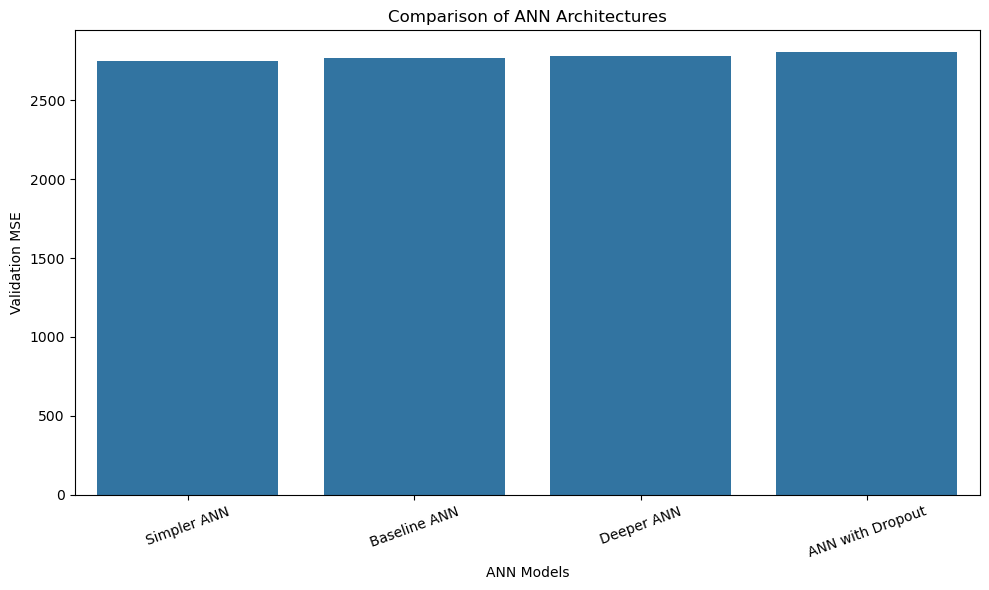

In [43]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=comparison,
    x="Model",
    y="Validation MSE"
)

plt.title("Comparison of ANN Architectures")
plt.xlabel("ANN Models")
plt.ylabel("Validation MSE")

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

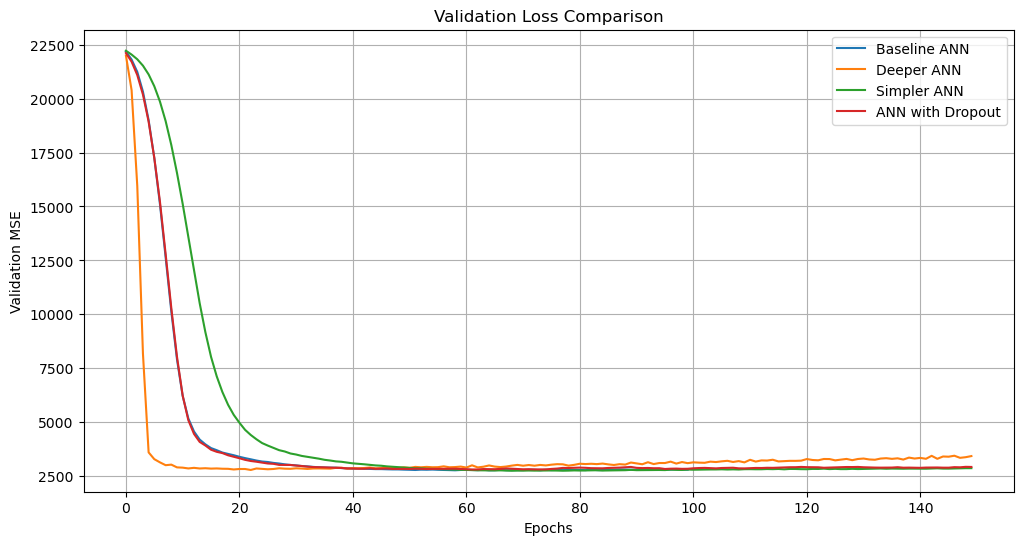

In [44]:
plt.figure(figsize=(12, 6))

plt.plot(history.history["val_loss"], label="Baseline ANN")
plt.plot(history_2.history["val_loss"], label="Deeper ANN")
plt.plot(history_3.history["val_loss"], label="Simpler ANN")
plt.plot(history_4.history["val_loss"], label="ANN with Dropout")

plt.title("Validation Loss Comparison")
plt.xlabel("Epochs")
plt.ylabel("Validation MSE")

plt.legend()
plt.grid(True)
plt.show()

Evaluate the best improved model

In [45]:
# Store models and histories

models = {
    "Baseline ANN": model,
    "Deeper ANN": model_2,
    "Simpler ANN": model_3,
    "ANN with Dropout": model_4
}

# Find the best model based on validation performance
best_model_name = comparison.iloc[0]["Model"]

best_model = models[best_model_name]

print("Best Model:", best_model_name)

Best Model: Simpler ANN


In [46]:
# Predict using the best model

best_predictions = best_model.predict(X_test_scaled).flatten()

# Calculate metrics

best_mse = mean_squared_error(y_test, best_predictions)
best_rmse = np.sqrt(best_mse)
best_mae = mean_absolute_error(y_test, best_predictions)
best_r2 = r2_score(y_test, best_predictions)

print("Best Model:", best_model_name)
print("MSE:", best_mse)
print("RMSE:", best_rmse)
print("MAE:", best_mae)
print("R2 Score:", best_r2)

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
Best Model: Simpler ANN
MSE: 2758.71962883586
RMSE: 52.52351500838324
MAE: 41.37552145625768
R2 Score: 0.47930528233581493


Compare baseline vs improved ANN

In [47]:
final_comparison = pd.DataFrame([
    {
        "Model": "Baseline ANN",
        "MSE": mse,
        "RMSE": rmse,
        "MAE": mae,
        "R2 Score": r2
    },
    {
        "Model": best_model_name,
        "MSE": best_mse,
        "RMSE": best_rmse,
        "MAE": best_mae,
        "R2 Score": best_r2
    }
])

final_comparison

,Model,MSE,RMSE,MAE,R2 Score
0,Baseline ANN,2850.588630,53.390904,42.824355,0.461965
1,Simpler ANN,2758.719629,52.523515,41.375521,0.479305


## Model Improvement and Comparison

Four ANN architectures were experimented with:

1. Baseline ANN: 64 and 32 neurons.
2. Deeper ANN: 128, 64 and 32 neurons.
3. Simpler ANN: 32 and 16 neurons.
4. ANN with Dropout: 64 and 32 neurons with 20% dropout.

The models were trained using the Adam optimizer and
Mean Squared Error loss function.

Their validation performance was compared to identify
the most suitable architecture.

The selected model was evaluated using the test dataset.

The results demonstrate that changing ANN architecture
and regularization can influence model performance.